# 02 — Descriptive Analysis

This notebook explores the cleaned residential real-estate transaction dataset and investigates the distributions, relationships and potential modelling implications of the available variables.

The objective is not to perform formal hypothesis testing or final feature selection. Instead, the analysis is used to:

- understand the structure and distribution of the variables;
- identify important geographic, structural and temporal patterns;
- investigate potential anomalies or unusual distributions;
- examine relationships between candidate predictors and transaction price;
- identify redundant variables and potential target leakage;
- define an initial modelling feature set for the subsequent modelling stage.

The analysis uses the cleaned dataset produced in `01_data_preparation.ipynb`.

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cleaned_df = pd.read_parquet("../data/cleaned_data.parquet")

cleaned_df.head()

,municipal_district,apaa_status,property_type,number_of_facades,zone_price_eur_per_m2,main_area_m2,auxiliary_area_m2,construction_year,floor,contract_date,transaction_price_eur,objective_value_proxy,price_per_m2_eur,within_appa,is_apartment,contract_year,contract_month,contract_day,contract_day_of_week,contract_quarter
0,ΑΓΙΑΣ ΒΑΡΒΑΡΑΣ,Within APPA,Apartment,1,900.0,84.67,13.0,1992.0,3,2017-09-13,49155.75,76203.0,580.556868,1,1,2017,9,13,2,3
1,ΑΓΙΑΣ ΒΑΡΒΑΡΑΣ,Within APPA,Apartment,2,900.0,84.50,0.0,1998.0,1,2017-11-02,60000.00,76050.0,710.059172,1,1,2017,11,2,3,4
2,ΑΓΙΑΣ ΒΑΡΒΑΡΑΣ,Within APPA,Apartment,2,900.0,150.59,0.0,2003.0,3,2017-12-29,135000.00,135531.0,896.473869,1,1,2017,12,29,4,4
3,ΑΓΙΑΣ ΠΑΡΑΣΚΕΥΗΣ,Within APPA,Apartment,0,1700.0,104.50,0.0,2010.0,4,2017-03-09,231618.12,177650.0,2216.441340,1,1,2017,3,9,3,1
4,ΑΓΙΑΣ ΠΑΡΑΣΚΕΥΗΣ,Within APPA,Apartment,1,1250.0,70.81,0.0,2004.0,1,2017-03-21,107322.77,88512.5,1515.644259,1,1,2017,3,21,1,1


## 2. Dataset overview

Before examining individual variables, the overall size, structure and data quality of the cleaned dataset are reviewed.

In [56]:
### 2.1 Dataset dimensions

In [57]:
print(f"Number of observations: {cleaned_df.shape[0]:,}")
print(f"Number of variables: {cleaned_df.shape[1]}")

Number of observations: 86,085
Number of variables: 20


The cleaned dataset contains 86,085 residential property transactions and 20 variables.

### 2.2 Data types and structure

In [58]:
cleaned_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 86085 entries, 0 to 86084
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   municipal_district     86085 non-null  str           
 1   apaa_status            86085 non-null  str           
 2   property_type          86085 non-null  str           
 3   number_of_facades      86085 non-null  int64         
 4   zone_price_eur_per_m2  86085 non-null  float64       
 5   main_area_m2           86085 non-null  float64       
 6   auxiliary_area_m2      86085 non-null  float64       
 7   construction_year      86085 non-null  float64       
 8   floor                  86085 non-null  int64         
 9   contract_date          86085 non-null  datetime64[us]
 10  transaction_price_eur  86085 non-null  float64       
 11  objective_value_proxy  86085 non-null  float64       
 12  price_per_m2_eur       86085 non-null  float64       
 13  within_appa 

The dataset contains a combination of categorical, numerical and temporal variables. The `contract_date` variable is stored as a datetime, while the derived temporal variables are represented numerically.

The cleaned dataset therefore provides a suitable starting point for exploratory analysis and subsequent modelling.

### 2.3 Descriptive statistics

In [59]:
cleaned_df.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

,count,mean,min,1%,5%,25%,50%,75%,95%,99%,max,std
number_of_facades,86085.0,1.115084,0.0,0.0,0.0,1.0,1.0,1.0,2.0,3.0,4.0,0.562349
zone_price_eur_per_m2,86085.0,1285.380496,250.0,340.0,530.0,950.0,1200.0,1500.0,2200.0,3800.0,10800.0,587.732768
main_area_m2,86085.0,78.227283,20.0,23.3,30.0,50.55,71.04,93.57,148.596,242.796,1399.05,45.594859
auxiliary_area_m2,86085.0,5.877461,0.0,0.0,0.0,0.0,0.0,0.0,29.544,91.7844,888.32,19.817678
construction_year,86085.0,1983.512668,1720.0,1928.0,1957.0,1971.0,1980.0,2003.0,2011.0,2019.0,2025.0,19.936278
floor,86085.0,1.827763,-1.0,-1.0,0.0,1.0,1.0,3.0,5.0,6.0,8.0,1.648322
contract_date,86085,2022-10-03 02:56:05.520125,2017-02-28 00:00:00,2017-05-22 00:00:00,2018-03-29 00:00:00,2020-10-20 00:00:00,2023-03-19 00:00:00,2024-11-18 00:00:00,2026-03-29 00:00:00,2026-07-08 00:00:00,2026-08-02 00:00:00,NaN
transaction_price_eur,86085.0,129527.11539,4357.78,17000.0,26802.836,52000.0,85000.0,140000.0,300000.0,725532.8096,46000000.0,370451.925718
objective_value_proxy,86085.0,104074.302704,6355.0,16529.5,27750.5,54279.0,81200.0,120450.0,241797.5,492628.0,4671170.0,110032.085204
price_per_m2_eur,86085.0,1582.401506,166.389351,359.970545,542.857143,860.955661,1211.203634,1808.066759,3333.333333,5958.046084,608695.652174,3971.00278


The summary statistics provide an initial overview of the numerical variables. Several variables, particularly property area and transaction price, show substantial differences between their central values and upper percentiles, suggesting the presence of right-skewed distributions and extended upper tails.

These characteristics are investigated in more detail in the univariate analysis below.

### 2.4 Missing values and duplicate observations

In [60]:
print("Missing values:")
display(cleaned_df.isna().sum())

print(f"Duplicate rows: {cleaned_df.duplicated().sum()}")

Missing values:


municipal_district       0
apaa_status              0
property_type            0
number_of_facades        0
zone_price_eur_per_m2    0
main_area_m2             0
auxiliary_area_m2        0
construction_year        0
floor                    0
contract_date            0
transaction_price_eur    0
objective_value_proxy    0
price_per_m2_eur         0
within_appa              0
is_apartment             0
contract_year            0
contract_month           0
contract_day             0
contract_day_of_week     0
contract_quarter         0
dtype: int64

Duplicate rows: 0


No missing values or duplicate rows remain in the cleaned modelling population.

The detailed decisions that resulted in this dataset are documented in `01_data_preparation.ipynb`.

## 3. Univariate analysis

This section examines the distribution of individual variables in the cleaned dataset.

Categorical and discrete variables are examined using frequency distributions, while numerical variables are assessed using descriptive statistics and histograms.

The focus is on understanding the composition of the dataset and identifying characteristics that may be relevant during modelling.

### 3.1 Municipal district

`municipal_district` represents the geographic district associated with the property of each transaction.

Because location is expected to play an important role in property valuation, the distribution of observations across districts is examined before investigating its relationship with transaction price.

In [61]:
cleaned_df["municipal_district"].describe()

count        86085
unique        3483
top       ΑΘΗΝΑΙΩΝ
freq          8159
Name: municipal_district, dtype: object

In [62]:
district_counts = cleaned_df["municipal_district"].value_counts()

display(district_counts.head(20))

print(
    f"Number of unique municipal districts: "
    f"{cleaned_df['municipal_district'].nunique():,}"
)

municipal_district
ΑΘΗΝΑΙΩΝ                          8159
ΘΕΣΣΑΛΟΝΙΚΗΣ                      2338
ΠΕΙΡΑΙΩΣ                          2166
ΚΑΛΛΙΘΕΑΣ                         1789
ΘΕΣΣΑΛΟΝΙΚΗΣ - 5 ΔΙΑΜ. ΘΕΣ/ΚΗΣ    1670
ΠΑΤΡΕΩΝ                           1647
ΑΘΗΝΑΙΩΝ - 6 ΔΙΑΜΕΡΙΣΜΑ           1607
ΑΘΗΝΑΙΩΝ - 1 ΔΙΑΜΕΡΙΣΜΑ           1207
ΖΩΓΡΑΦΟΥ                          1128
ΓΛΥΦΑΔΑΣ                          1093
ΘΕΣΣΑΛΟΝΙΚΗΣ - 1 ΔΙΑΜ. ΘΕΣ/ΚΗΣ    1075
ΠΑΛΑΙΟΥ ΦΑΛΗΡΟΥ                   1010
ΑΘΗΝΑΙΩΝ - 7 ΔΙΑΜΕΡΙΣΜΑ           1006
ΑΘΗΝΑΙΩΝ - 2 ΔΙΑΜΕΡΙΣΜΑ            973
ΝΕΑΣ ΣΜΥΡΝΗΣ                       950
ΑΘΗΝΑΙΩΝ - 5 ΔΙΑΜΕΡΙΣΜΑ            876
ΑΜΑΡΟΥΣΙΟΥ (ΜΑΡΟΥΣΙ)               847
ΚΑΛΑΜΑΡΙΑΣ                         841
ΠΕΡΙΣΤΕΡΙΟΥ                        838
ΧΑΛΑΝΔΡΙΟΥ                         786
Name: count, dtype: int64

Number of unique municipal districts: 3,483


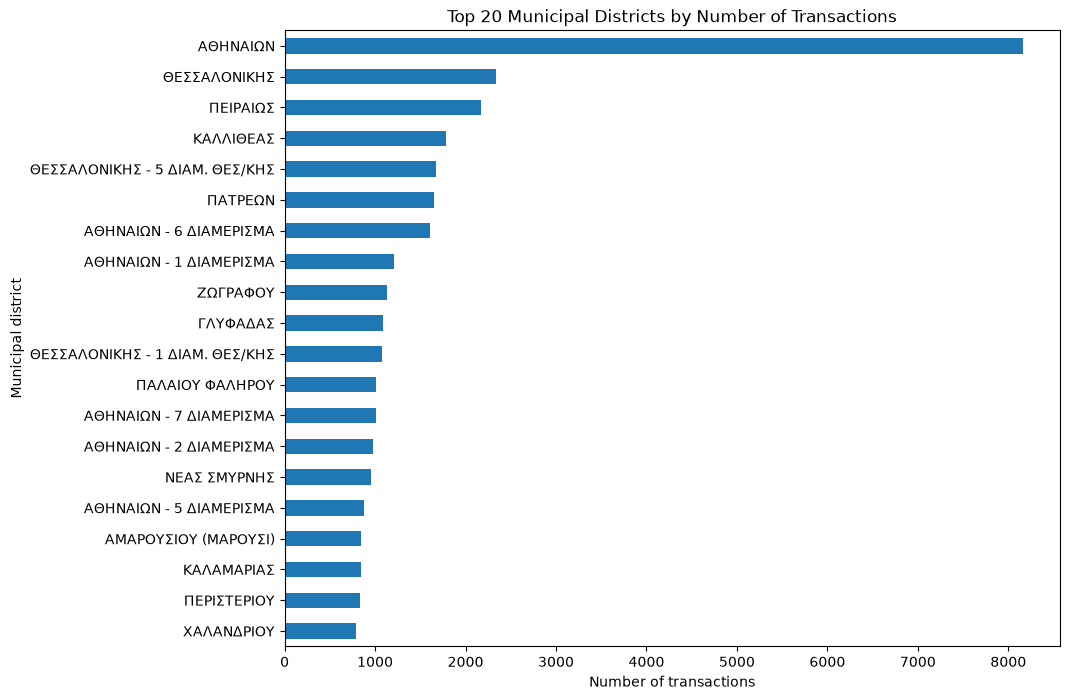

In [63]:
district_counts.head(20).sort_values().plot(
    kind="barh",
    figsize=(10, 8)
)

plt.xlabel("Number of transactions")
plt.ylabel("Municipal district")
plt.title("Top 20 Municipal Districts by Number of Transactions")
plt.show()

The dataset contains 3,483 distinct municipal districts. `ΑΘΗΝΑΙΩΝ` is the most frequent district, but accounts for approximately 9.5% of all observations.

The dataset is therefore geographically diverse rather than being dominated by a single municipal district. This suggests that geographic information may be important for modelling, while the high number of distinct districts will require careful handling of this high-cardinality categorical variable.

### 3.2 APPA status

The distribution of properties within and outside APPA areas is examined to understand the composition of the dataset.

In [64]:
appa_counts = cleaned_df["apaa_status"].value_counts()

display(appa_counts)
display((appa_counts / len(cleaned_df) * 100).round(2))

apaa_status
Within APPA     79803
Outside APPA     6282
Name: count, dtype: int64

apaa_status
Within APPA     92.7
Outside APPA     7.3
Name: count, dtype: float64

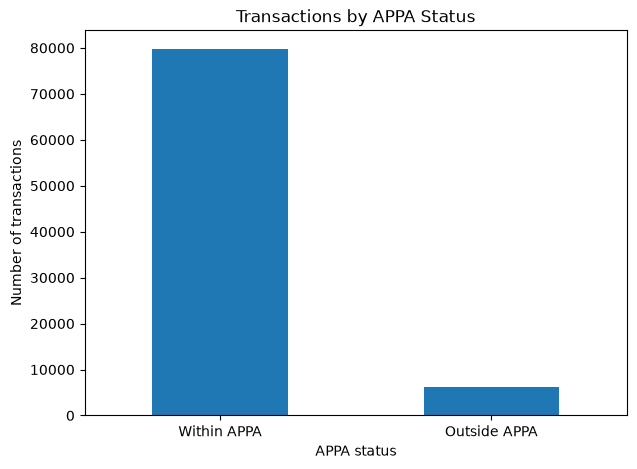

In [65]:
appa_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.xlabel("APPA status")
plt.ylabel("Number of transactions")
plt.title("Transactions by APPA Status")
plt.xticks(rotation=0)
plt.show()

Approximately 93% of observations are within APPA areas, while approximately 7% are outside.

The modelling population is therefore strongly concentrated within APPA areas. The variable may nevertheless contain useful information because APPA status can capture differences in the valuation context of the property.

### 3.3 Property type

The distribution of property types is examined to understand the composition of the residential transactions included in the modelling population.

In [66]:
property_counts = cleaned_df["property_type"].value_counts()

display(property_counts)
display((property_counts / len(cleaned_df) * 100).round(2))

property_type
Apartment         75187
Detached house    10898
Name: count, dtype: int64

property_type
Apartment         87.34
Detached house    12.66
Name: count, dtype: float64

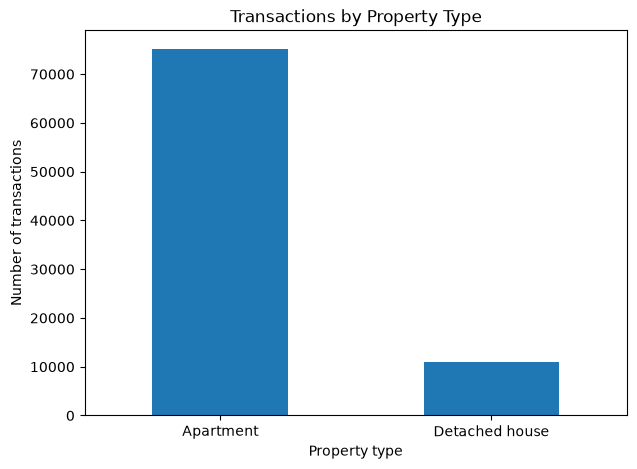

In [67]:
property_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.xlabel("Property type")
plt.ylabel("Number of transactions")
plt.title("Transactions by Property Type")
plt.xticks(rotation=0)
plt.show()

Apartments account for approximately 87% of the modelling population, while detached houses account for approximately 13%.

The dataset is therefore substantially more representative of apartment transactions. Property type may still provide useful predictive information because apartments and detached houses represent structurally different types of residential property.

### 3.4 Number of facades

The number of recorded facades is examined to understand its distribution and whether particular categories are especially rare.

In [68]:
facade_counts = cleaned_df["number_of_facades"].value_counts().sort_index()

display(facade_counts)
display((facade_counts / len(cleaned_df) * 100).round(2))

number_of_facades
0     8060
1    61137
2    15898
3      901
4       89
Name: count, dtype: int64

number_of_facades
0     9.36
1    71.02
2    18.47
3     1.05
4     0.10
Name: count, dtype: float64

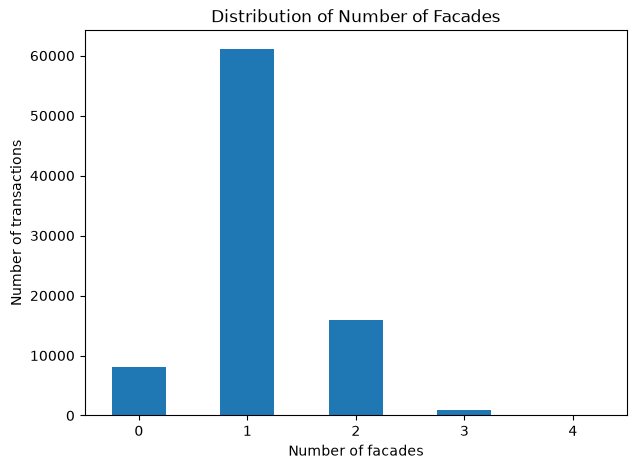

In [69]:
facade_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.xlabel("Number of facades")
plt.ylabel("Number of transactions")
plt.title("Distribution of Number of Facades")
plt.xticks(rotation=0)
plt.show()

The variable is highly concentrated at one facade, which accounts for approximately 71% of observations. Around 9% of observations have zero recorded facades, 18% two, while three or four facades are uncommon.

The concentration in a small number of categories should be considered when interpreting the variable during modelling. The zero category is retained at this stage because its exact meaning in the source data is not sufficiently documented to justify treating it as erroneous.

### 3.5 Zone price

`zone_price_eur_per_m2` represents the recorded zone price associated with the transaction location.

Its distribution is examined because it provides geographically structured valuation information that may be relevant to transaction price.

In [70]:
cleaned_df["zone_price_eur_per_m2"].describe(
    percentiles=[
        0.01, 0.05, 0.10,
        0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

count    86085.000000
mean      1285.380496
std        587.732768
min        250.000000
1%         340.000000
5%         530.000000
10%        700.000000
25%        950.000000
50%       1200.000000
75%       1500.000000
90%       1900.000000
95%       2200.000000
99%       3800.000000
max      10800.000000
Name: zone_price_eur_per_m2, dtype: float64

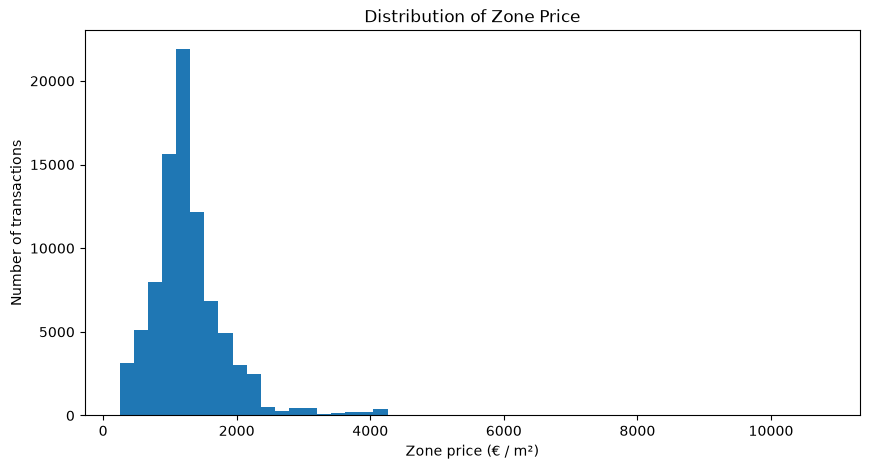

In [71]:
plt.figure(figsize=(10, 5))

plt.hist(
    cleaned_df["zone_price_eur_per_m2"],
    bins=50
)

plt.xlabel("Zone price (€ / m²)")
plt.ylabel("Number of transactions")
plt.title("Distribution of Zone Price")
plt.show()

Zone prices have a median of approximately €1,200/m² and a mean of approximately €1,285/m².

The distribution is positively skewed, with an upper tail extending to €10,800/m². The 99th percentile is approximately €3,800/m².

The substantial variation in zone price suggests that it may provide useful location-related information for predicting transaction price.

### 3.6 Main area

The main area of the property is examined as one of the primary structural characteristics of the transaction.

In [72]:
cleaned_df["main_area_m2"].describe(
    percentiles=[
        0.01, 0.05, 0.10,
        0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

count    86085.000000
mean        78.227283
std         45.594859
min         20.000000
1%          23.300000
5%          30.000000
10%         36.700000
25%         50.550000
50%         71.040000
75%         93.570000
90%        121.892000
95%        148.596000
99%        242.796000
max       1399.050000
Name: main_area_m2, dtype: float64

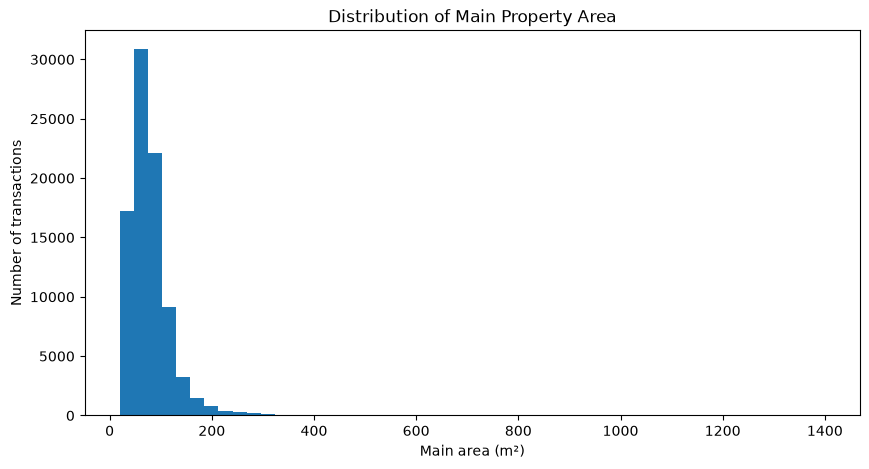

In [73]:
plt.figure(figsize=(10, 5))

plt.hist(
    cleaned_df["main_area_m2"],
    bins=50
)

plt.xlabel("Main area (m²)")
plt.ylabel("Number of transactions")
plt.title("Distribution of Main Property Area")
plt.show()

The median main area is approximately 71 m², with the middle 50% of observations ranging from approximately 51 to 94 m².

The distribution has a pronounced right tail, with some properties substantially larger than the typical residential property and a maximum recorded area of approximately 1,399 m².

The variable is expected to be an important predictor of transaction price, although the relationship may not be purely linear.

### 3.7 Auxiliary area

The distribution of auxiliary area is examined separately because the variable contains a large number of zero values.

In [74]:
cleaned_df["auxiliary_area_m2"].describe(
    percentiles=[
        0.01, 0.05, 0.10,
        0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

count    86085.000000
mean         5.877461
std         19.817678
min          0.000000
1%           0.000000
5%           0.000000
10%          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
90%         15.600000
95%         29.544000
99%         91.784400
max        888.320000
Name: auxiliary_area_m2, dtype: float64

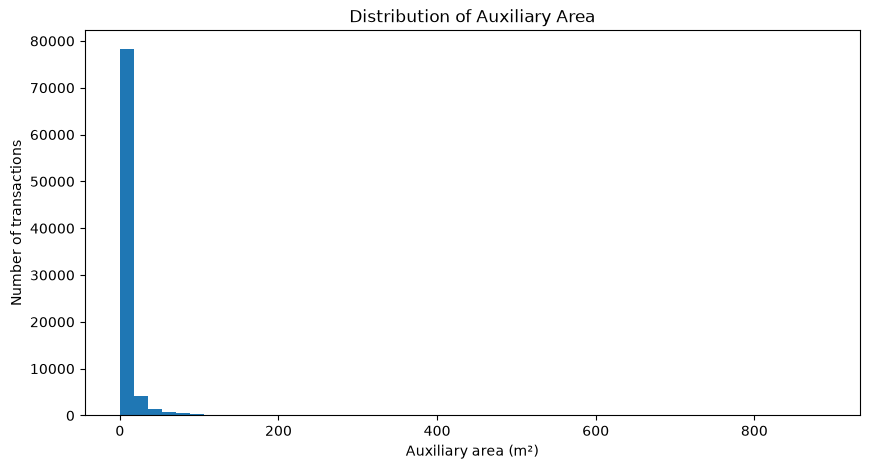

In [75]:
plt.figure(figsize=(10, 5))

plt.hist(
    cleaned_df["auxiliary_area_m2"],
    bins=50
)

plt.xlabel("Auxiliary area (m²)")
plt.ylabel("Number of transactions")
plt.title("Distribution of Auxiliary Area")
plt.show()

At least 75% of observations have zero recorded auxiliary area. Among observations with positive auxiliary area, the distribution is strongly right-skewed, with a 99th percentile of approximately 92 m² and a maximum of approximately 888 m².

The zero values reflect the data-preparation assumption that missing auxiliary-area measurements represent no recorded auxiliary area. This interpretation should therefore be kept in mind when evaluating the variable during modelling.

### 3.8 Construction year

The distribution of construction year is examined to understand the age profile of the residential properties in the dataset.

In [76]:
cleaned_df["construction_year"].describe(
    percentiles=[
        0.01, 0.05, 0.10,
        0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

count    86085.000000
mean      1983.512668
std         19.936278
min       1720.000000
1%        1928.000000
5%        1957.000000
10%       1962.400000
25%       1971.000000
50%       1980.000000
75%       2003.000000
90%       2009.000000
95%       2011.000000
99%       2019.000000
max       2025.000000
Name: construction_year, dtype: float64

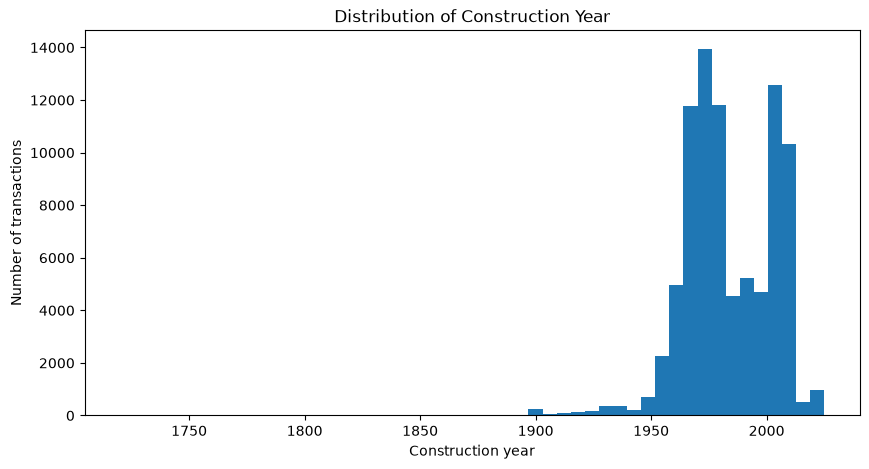

In [77]:
plt.figure(figsize=(10, 5))

plt.hist(
    cleaned_df["construction_year"],
    bins=50
)

plt.xlabel("Construction year")
plt.ylabel("Number of transactions")
plt.title("Distribution of Construction Year")
plt.show()

The median construction year is 1980, with half of the observations corresponding to properties constructed between approximately 1971 and 2003.

The dataset therefore contains a substantial amount of older housing stock, while the upper tail extends to recently constructed properties.

Construction year may provide information about property age, although its predictive contribution may depend on other characteristics such as location and property size.

### 3.9 Floor

The floor variable is examined as a discrete property characteristic. The source value `Υ` was converted to `-1` during data preparation to preserve the information in a numerical representation.

In [78]:
floor_counts = cleaned_df["floor"].value_counts().sort_index()

display(floor_counts)
display((floor_counts / len(cleaned_df) * 100).round(2))

floor
-1     1149
 0    17878
 1    25560
 2    15997
 3    11398
 4     7313
 5     4275
 6     1698
 7      607
 8      210
Name: count, dtype: int64

floor
-1     1.33
 0    20.77
 1    29.69
 2    18.58
 3    13.24
 4     8.50
 5     4.97
 6     1.97
 7     0.71
 8     0.24
Name: count, dtype: float64

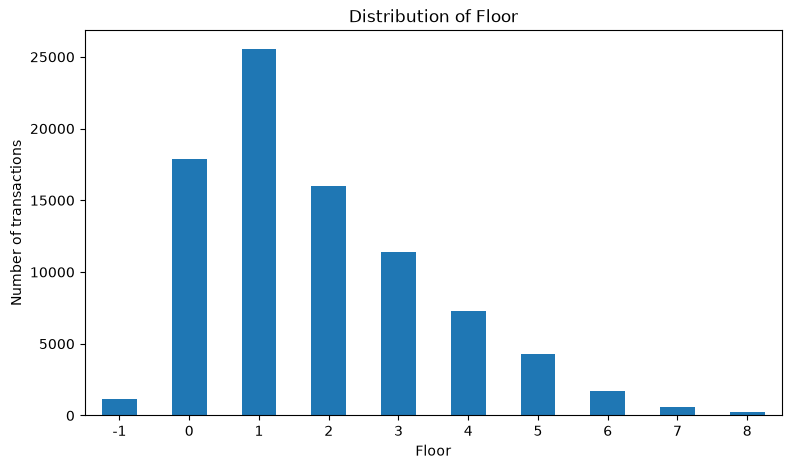

In [79]:
floor_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.xlabel("Floor")
plt.ylabel("Number of transactions")
plt.title("Distribution of Floor")
plt.xticks(rotation=0)
plt.show()

The floor distribution is concentrated at lower levels. The first floor is the most common category, while ground-floor and basement-level observations are also substantial. Higher floors become progressively less frequent, with approximately 1% of observations at floor 6 or above.

Because floor is an ordinal and discrete variable, its relationship with transaction price may not be adequately represented by a simple linear effect.

### 3.10 Transaction price

`transaction_price_eur` is the target variable for the subsequent modelling stage.

Its distribution is examined carefully because the shape and presence of extreme values will influence the choice and evaluation of predictive models.

In [80]:
cleaned_df["transaction_price_eur"].describe(
    percentiles=[
        0.01, 0.05, 0.10,
        0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

count    8.608500e+04
mean     1.295271e+05
std      3.704519e+05
min      4.357780e+03
1%       1.700000e+04
5%       2.680284e+04
10%      3.500000e+04
25%      5.200000e+04
50%      8.500000e+04
75%      1.400000e+05
90%      2.473545e+05
95%      3.000000e+05
99%      7.255328e+05
max      4.600000e+07
Name: transaction_price_eur, dtype: float64

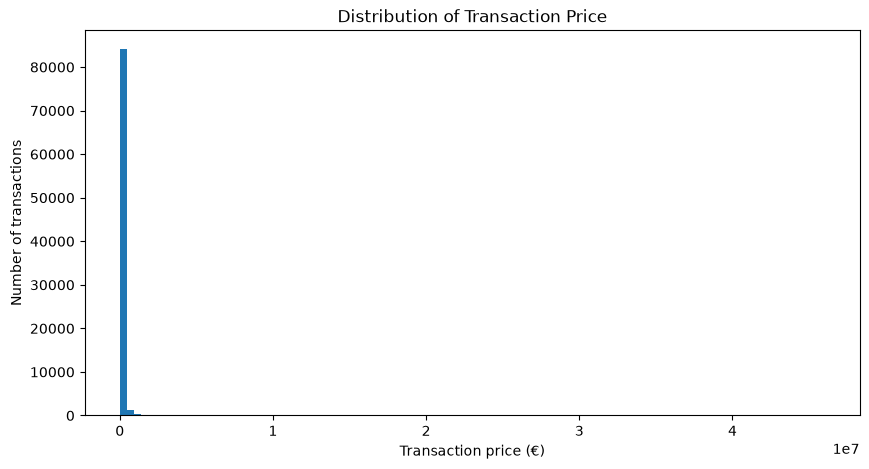

In [81]:
plt.figure(figsize=(10, 5))

plt.hist(
    cleaned_df["transaction_price_eur"],
    bins=100
)

plt.xlabel("Transaction price (€)")
plt.ylabel("Number of transactions")
plt.title("Distribution of Transaction Price")
plt.show()

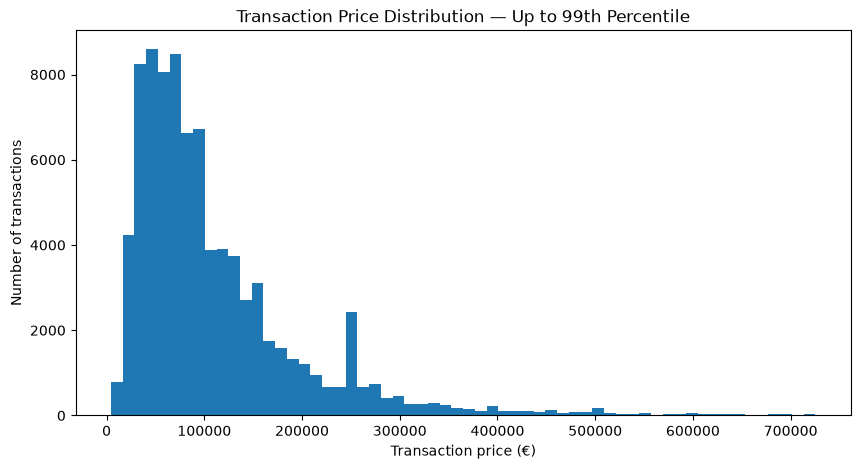

99th percentile: €725,532.81


In [82]:
price_99 = cleaned_df["transaction_price_eur"].quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    cleaned_df.loc[
        cleaned_df["transaction_price_eur"] <= price_99,
        "transaction_price_eur"
    ],
    bins=60
)

plt.xlabel("Transaction price (€)")
plt.ylabel("Number of transactions")
plt.title("Transaction Price Distribution — Up to 99th Percentile")
plt.show()

print(f"99th percentile: €{price_99:,.2f}")

Transaction price is strongly positively skewed. The median transaction price is approximately €85,000, compared with a mean of approximately €129,500.

The upper 1% of transactions exceed approximately €725,500, while the maximum recorded transaction price is €46 million.

The upper tail is retained in the dataset because statistical extremeness alone does not establish that an observation is erroneous. The 99th-percentile restriction is used only to improve the readability of selected visualizations; these observations remain part of the modelling population.

## 4. Temporal analysis

The transaction data spans 2017–2026. Temporal distributions are examined to understand the coverage of the dataset and identify potential changes in transaction activity over time.

The 2026 data should be interpreted carefully because the available observations currently extend only through August 2, 2026.

### 4.1 Transactions by year

In [83]:
year_counts = cleaned_df["contract_year"].value_counts().sort_index()

display(year_counts)
display((year_counts / len(cleaned_df) * 100).round(2))

contract_year
2017     3313
2018     5752
2019     7727
2020     6213
2021     8910
2022     9113
2023    11611
2024    13749
2025    13084
2026     6613
Name: count, dtype: int64

contract_year
2017     3.85
2018     6.68
2019     8.98
2020     7.22
2021    10.35
2022    10.59
2023    13.49
2024    15.97
2025    15.20
2026     7.68
Name: count, dtype: float64

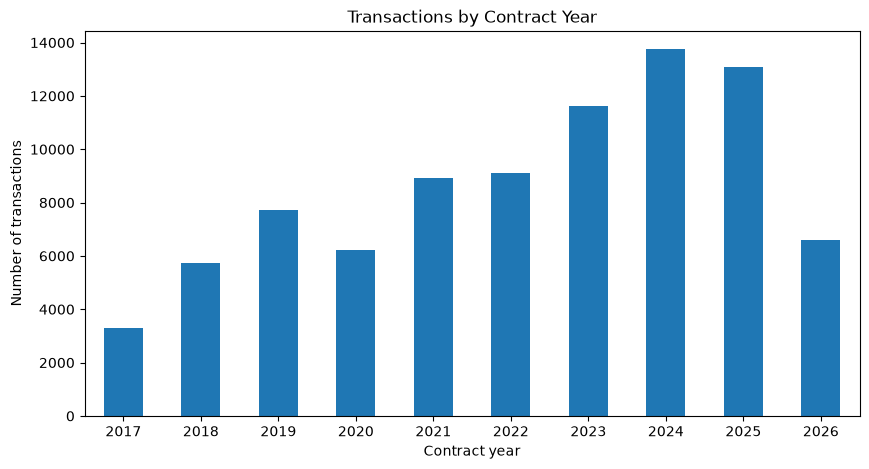

In [84]:
year_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Contract year")
plt.ylabel("Number of transactions")
plt.title("Transactions by Contract Year")
plt.xticks(rotation=0)
plt.show()

The number of observations generally increases in the later years of the dataset, with 2024 and 2025 containing the largest numbers of transactions.

The lower number of observations in 2026 should not be interpreted as lower annual transaction activity because the available 2026 data covers only part of the year.

### 4.2 Transactions by month

In [85]:
month_counts = cleaned_df["contract_month"].value_counts().sort_index()

display(month_counts)
display((month_counts / len(cleaned_df) * 100).round(2))

contract_month
1      5096
2      6833
3      7896
4      6602
5      7551
6      8563
7     10851
8      3227
9      6080
10     7057
11     7464
12     8865
Name: count, dtype: int64

contract_month
1      5.92
2      7.94
3      9.17
4      7.67
5      8.77
6      9.95
7     12.60
8      3.75
9      7.06
10     8.20
11     8.67
12    10.30
Name: count, dtype: float64

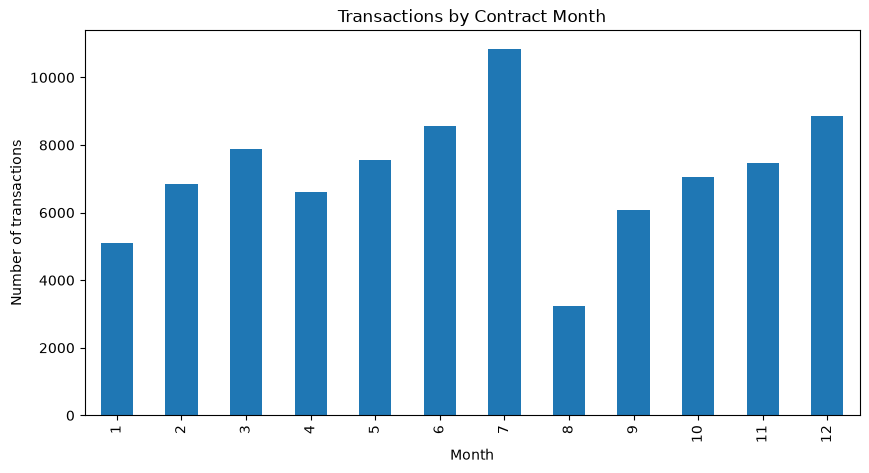

In [86]:
month_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Month")
plt.ylabel("Number of transactions")
plt.title("Transactions by Contract Month")
plt.xticks(range(12), range(1, 13))
plt.show()

Transaction counts vary across months rather than being uniformly distributed. July has the highest share of observations, while August has the lowest.

This pattern may reflect differences in transaction activity, administrative processes or reporting coverage. It should therefore not automatically be interpreted as evidence of market seasonality.

### 4.3 Transactions by day of week

In [87]:
weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_counts = (
    cleaned_df["contract_day_of_week"]
    .value_counts()
    .sort_index()
)

weekday_counts.index = weekday_counts.index.map(weekday_names)

display(weekday_counts)
display((weekday_counts / len(cleaned_df) * 100).round(2))

contract_day_of_week
Monday       14966
Tuesday      16656
Wednesday    19382
Thursday     19413
Friday         995
Saturday       207
Sunday       14466
Name: count, dtype: int64

contract_day_of_week
Monday       17.39
Tuesday      19.35
Wednesday    22.51
Thursday     22.55
Friday        1.16
Saturday      0.24
Sunday       16.80
Name: count, dtype: float64

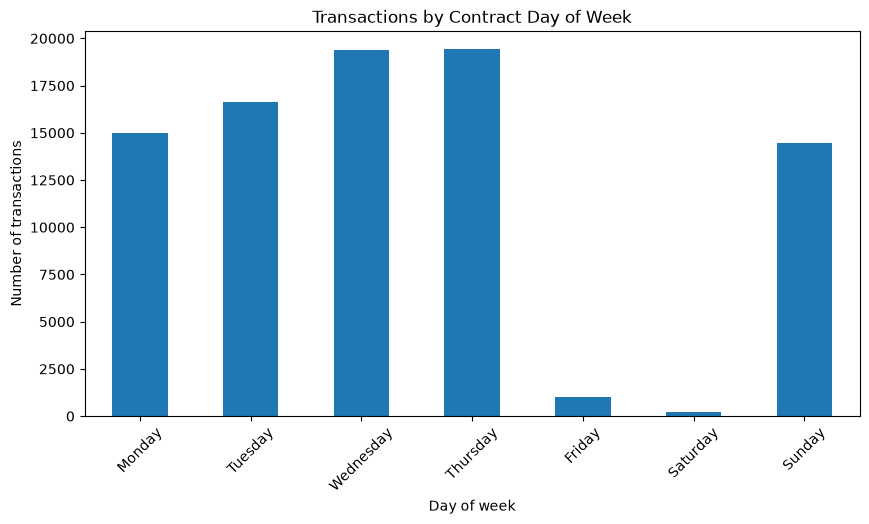

In [88]:
weekday_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Day of week")
plt.ylabel("Number of transactions")
plt.title("Transactions by Contract Day of Week")
plt.xticks(rotation=45)
plt.show()

The distribution across days of the week is unusual, particularly because Sunday represents a substantial share of observations while Friday and Saturday are relatively uncommon.

The pattern was found to be highly consistent across years rather than being driven by a single-year anomaly. However, without definitive documentation of the exact meaning and recording process of `contract_date`, the distribution should not be interpreted as evidence that transactions physically took place on those days.

This supports treating the temporal information at a coarser year/month level for the initial modelling scenario.

## 5. Price per m²

Price per square metre is examined as a descriptive metric because it provides an interpretable way to compare transaction values across properties of different sizes.

It is not considered a candidate predictor of transaction price because it is calculated directly from the target variable.

In [89]:
cleaned_df["price_per_m2_eur"].describe(
    percentiles=[
        0.01, 0.05,
        0.25, 0.50, 0.75,
        0.95, 0.99
    ]
)

count     86085.000000
mean       1582.401506
std        3971.002780
min         166.389351
1%          359.970545
5%          542.857143
25%         860.955661
50%        1211.203634
75%        1808.066759
95%        3333.333333
99%        5958.046084
max      608695.652174
Name: price_per_m2_eur, dtype: float64

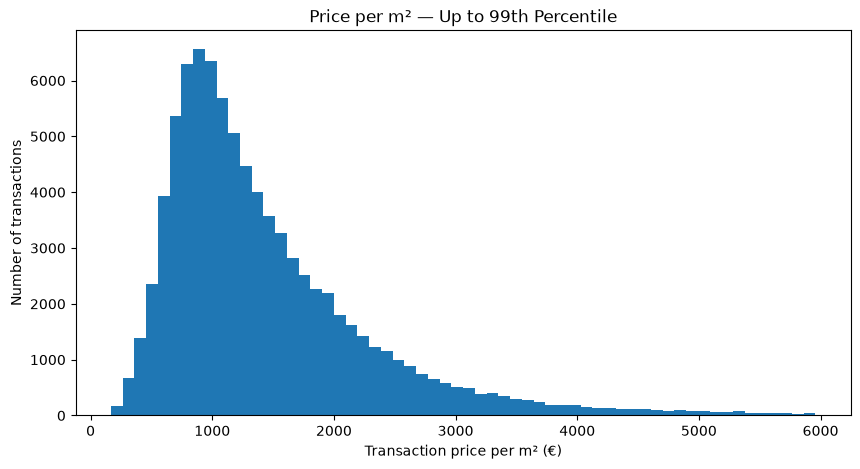

99th percentile: €5,958.05/m²


In [90]:
ppm_99 = cleaned_df["price_per_m2_eur"].quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    cleaned_df.loc[
        cleaned_df["price_per_m2_eur"] <= ppm_99,
        "price_per_m2_eur"
    ],
    bins=60
)

plt.xlabel("Transaction price per m² (€)")
plt.ylabel("Number of transactions")
plt.title("Price per m² — Up to 99th Percentile")
plt.show()

print(f"99th percentile: €{ppm_99:,.2f}/m²")

Price per m² is useful for descriptive analysis, but it must not be used as a predictor of transaction price because it is directly calculated from the target:

`price_per_m2_eur = transaction_price_eur / main_area_m2`

Including this variable as a predictor would therefore introduce target leakage.

## 6. Bivariate analysis

The following section investigates relationships between candidate predictors and transaction price.

Because transaction price has a substantial upper tail, observations above the 99th percentile are excluded from these visualizations where necessary to improve readability. These observations remain in the underlying dataset and are not removed from the modelling population.

The purpose of the analysis is to identify patterns, nonlinearities, heterogeneity and potential modelling issues rather than to establish causal relationships.

In [91]:
price_99 = cleaned_df["transaction_price_eur"].quantile(0.99)

plot_df = cleaned_df[
    cleaned_df["transaction_price_eur"] <= price_99
].copy()

print(f"Observations used for visualization: {len(plot_df):,}")
print(f"Excluded from plots only: {len(cleaned_df) - len(plot_df):,}")

Observations used for visualization: 85,224
Excluded from plots only: 861


### 6.1 Main area vs transaction price

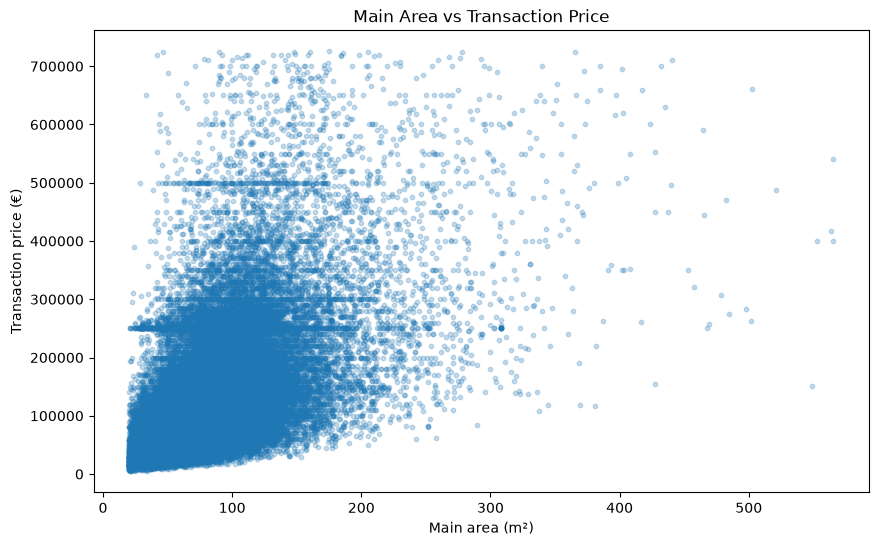

In [92]:
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_df["main_area_m2"],
    plot_df["transaction_price_eur"],
    alpha=0.25,
    s=10
)

plt.xlabel("Main area (m²)")
plt.ylabel("Transaction price (€)")
plt.title("Main Area vs Transaction Price")
plt.show()

A clear positive relationship is visible between main area and transaction price: larger properties generally have higher transaction prices.

The relationship is not purely linear, and the spread of transaction prices increases as property size increases. This fan-shaped pattern suggests heteroscedasticity and indicates that nonlinear modelling or transformations may be useful during the modelling stage.

### 6.2 Zone price vs transaction price

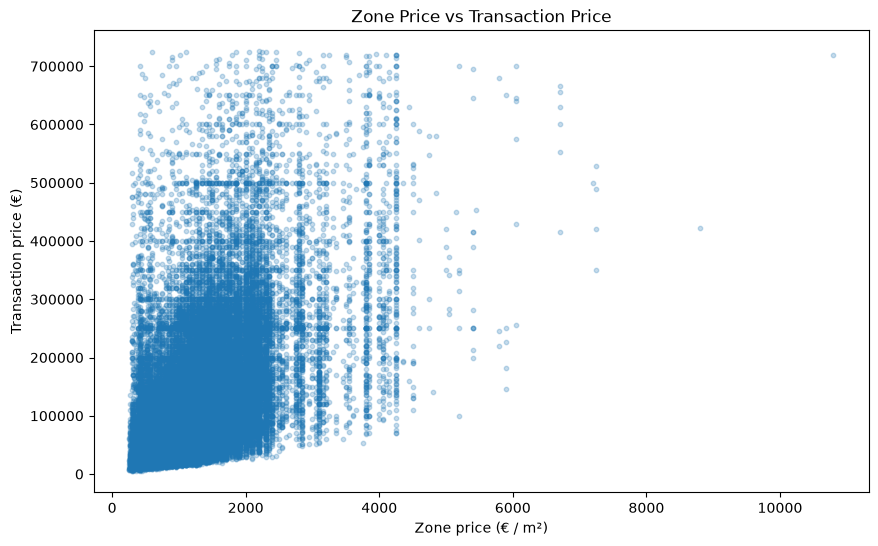

In [93]:
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_df["zone_price_eur_per_m2"],
    plot_df["transaction_price_eur"],
    alpha=0.25,
    s=10
)

plt.xlabel("Zone price (€ / m²)")
plt.ylabel("Transaction price (€)")
plt.title("Zone Price vs Transaction Price")
plt.show()

Higher zone prices are generally associated with higher transaction prices, although substantial variation remains within individual zone-price levels.

The vertical structure in the plot is consistent with the fact that the dataset contains a relatively limited number of unique zone-price values.

### 6.3 Objective-value proxy vs transaction price

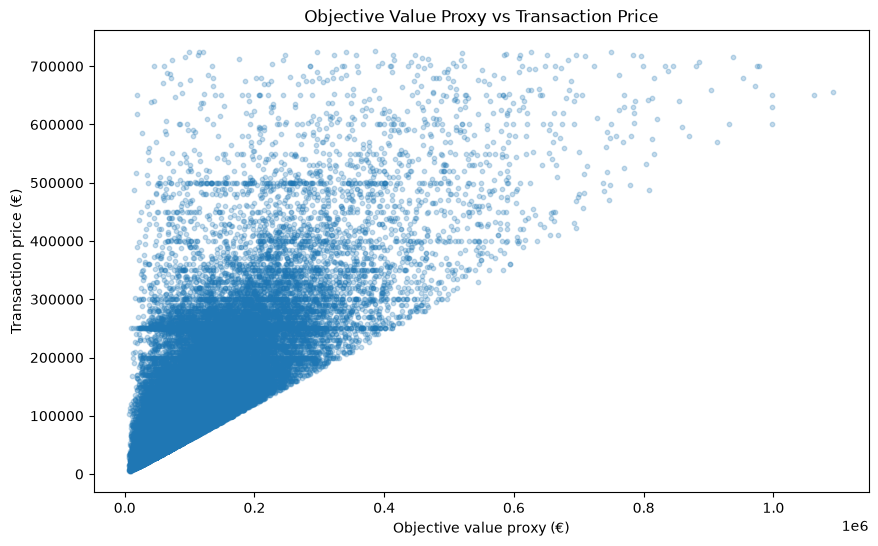

In [94]:
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_df["objective_value_proxy"],
    plot_df["transaction_price_eur"],
    alpha=0.25,
    s=10
)

plt.xlabel("Objective value proxy (€)")
plt.ylabel("Transaction price (€)")
plt.title("Objective Value Proxy vs Transaction Price")
plt.show()

A strong positive relationship is visible between the objective-value proxy and transaction price.

However, this relationship must be interpreted carefully because the objective-value proxy was also used during data preparation to define the 60% transaction-price filtering criterion:

`transaction_price_eur >= 0.60 × objective_value_proxy`

Consequently, the lower boundary visible in the scatter plot is partly a mechanical consequence of the sample-selection rule rather than an independently observed market relationship.

The variable is therefore retained as a candidate predictor, but its role and interpretation will require particular attention during modelling.

### 6.4 Auxiliary area vs transaction price

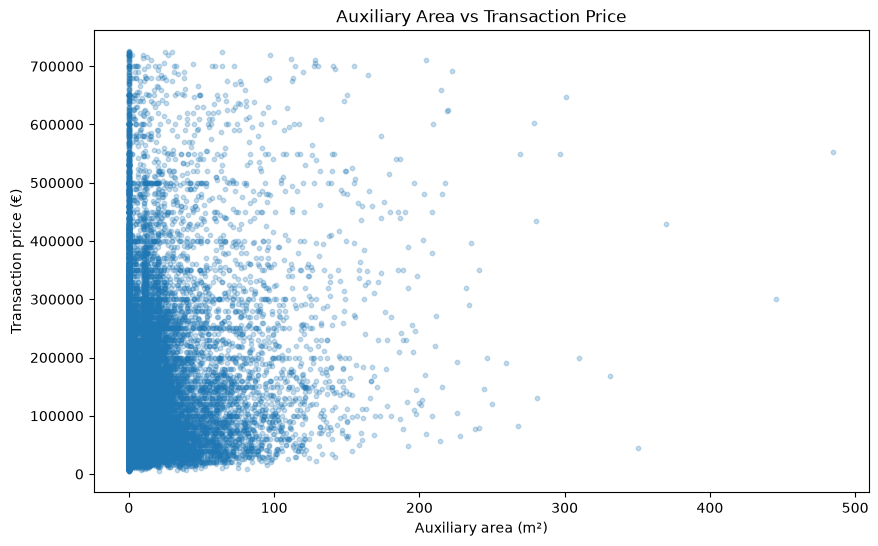

In [95]:
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_df["auxiliary_area_m2"],
    plot_df["transaction_price_eur"],
    alpha=0.25,
    s=10
)

plt.xlabel("Auxiliary area (m²)")
plt.ylabel("Transaction price (€)")
plt.title("Auxiliary Area vs Transaction Price")
plt.show()

The large concentration of observations at zero auxiliary area is clearly visible.

Among properties with positive auxiliary area, the relationship with transaction price appears relatively weak compared with the relationships observed for main area and zone price.

Nevertheless, auxiliary area is retained as a candidate predictor because its effect may depend on other property characteristics.

### 6.5 Construction year vs transaction price

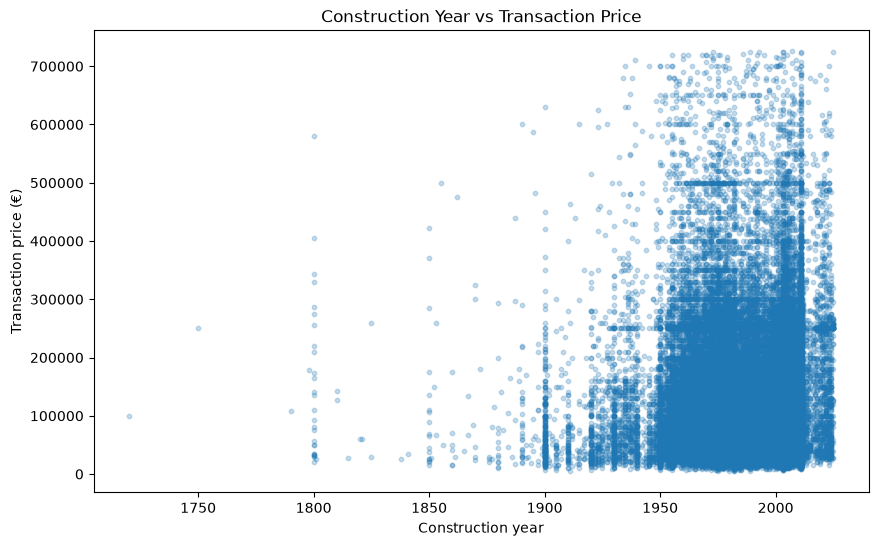

In [96]:
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_df["construction_year"],
    plot_df["transaction_price_eur"],
    alpha=0.25,
    s=10
)

plt.xlabel("Construction year")
plt.ylabel("Transaction price (€)")
plt.title("Construction Year vs Transaction Price")
plt.show()

The marginal relationship between construction year and transaction price appears relatively weak compared with variables such as main area and zone price.

However, a weak marginal relationship does not imply that construction year has no predictive value. Its contribution may become more apparent after accounting for geographic and structural characteristics.

### 6.6 Floor vs transaction price

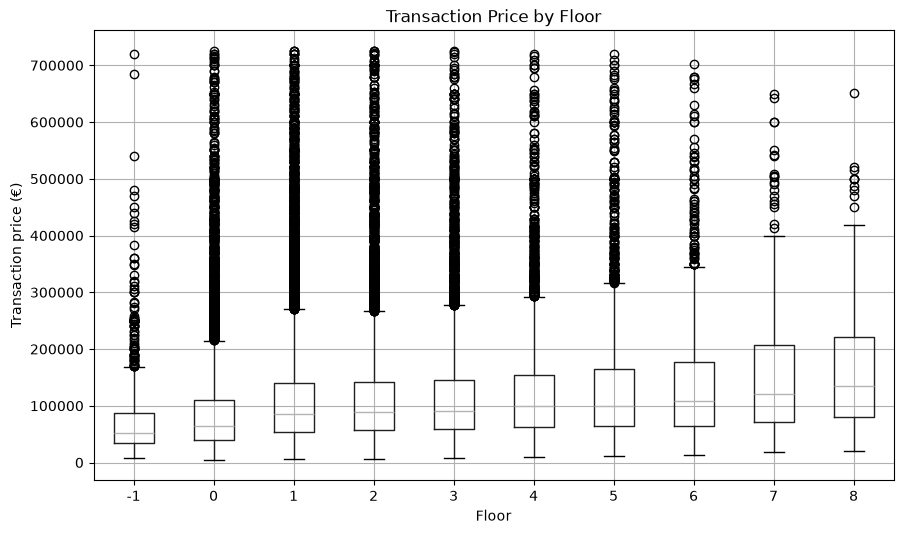

In [97]:
plot_df.boxplot(
    column="transaction_price_eur",
    by="floor",
    figsize=(10, 6)
)

plt.xlabel("Floor")
plt.ylabel("Transaction price (€)")
plt.title("Transaction Price by Floor")
plt.suptitle("")
plt.show()

Transaction prices show some variation across floors, with a modest upward pattern toward higher floors.

The points beyond the boxplot whiskers represent observations that are unusual relative to the distribution within their floor category. They should not automatically be interpreted as erroneous observations.

### 6.7 Property type vs transaction price

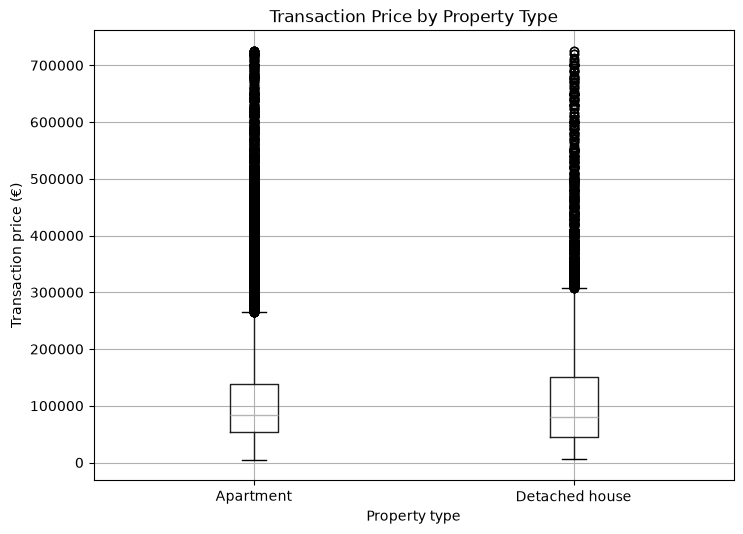

In [98]:
plot_df.boxplot(
    column="transaction_price_eur",
    by="property_type",
    figsize=(8, 6)
)

plt.xlabel("Property type")
plt.ylabel("Transaction price (€)")
plt.title("Transaction Price by Property Type")
plt.suptitle("")
plt.show()

The transaction-price distributions of apartments and detached houses differ, although the difference is modest relative to the overall variation in transaction prices.

Property type therefore appears to contain potentially useful information, but its contribution should be evaluated jointly with variables such as area and geographic characteristics.

### 6.8 APPA status vs transaction price

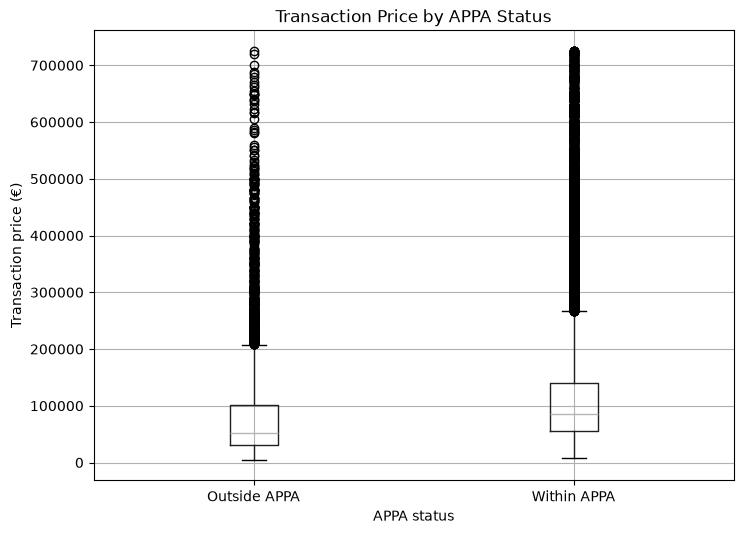

In [99]:
plot_df.boxplot(
    column="transaction_price_eur",
    by="apaa_status",
    figsize=(8, 6)
)

plt.xlabel("APPA status")
plt.ylabel("Transaction price (€)")
plt.title("Transaction Price by APPA Status")
plt.suptitle("")
plt.show()

Properties within APPA areas show somewhat higher transaction-price distributions than properties outside APPA areas.

This difference should be interpreted alongside the strong imbalance between the two groups and the geographic structure of APPA coverage.

### 6.9 Municipal district vs transaction price

Because the dataset contains 3,483 distinct municipal districts, displaying all districts in a single visualization would be difficult to interpret.

The following analysis therefore focuses on the 20 most frequently observed districts for descriptive purposes. This restriction applies only to the visualization and does not remove other districts from the modelling dataset.

In [100]:
top_districts = (
    cleaned_df["municipal_district"]
    .value_counts()
    .head(20)
    .index
)

district_plot_df = plot_df[
    plot_df["municipal_district"].isin(top_districts)
].copy()

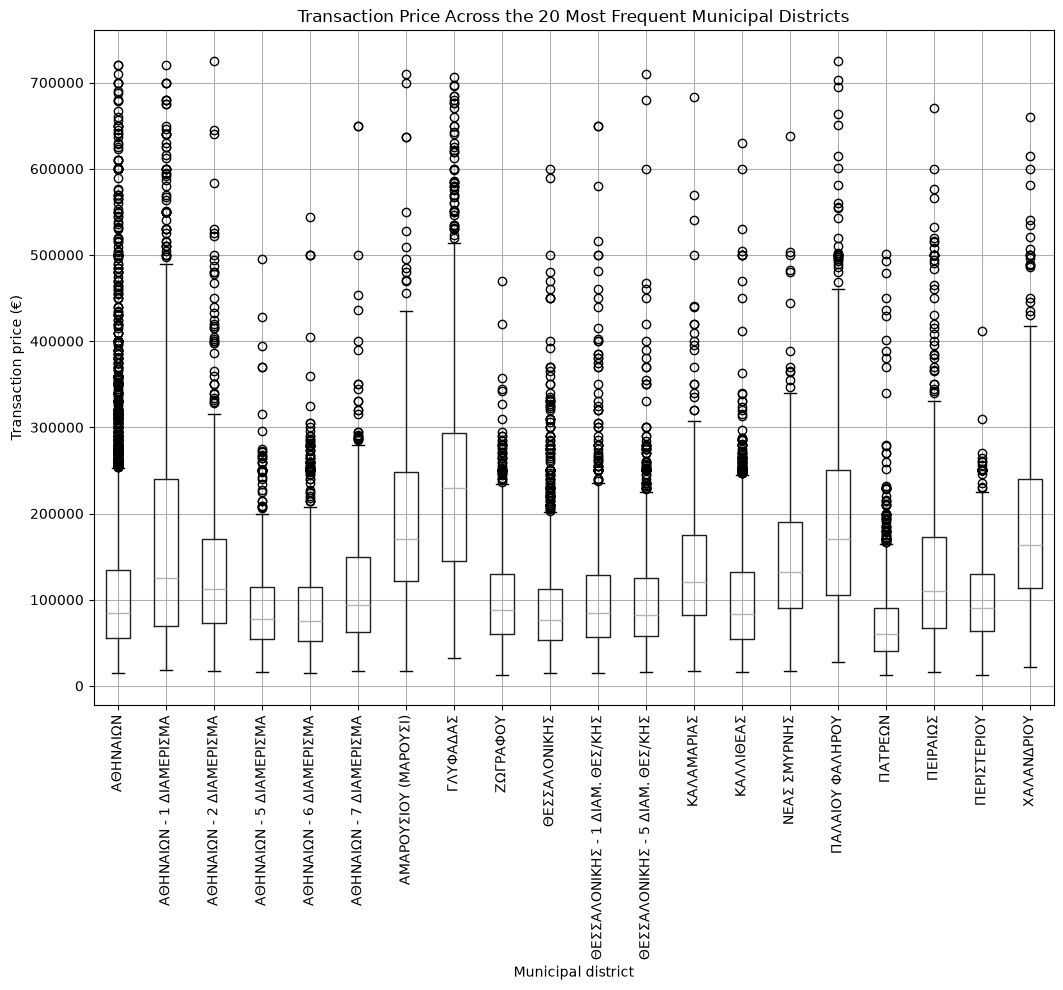

In [101]:
district_plot_df.boxplot(
    column="transaction_price_eur",
    by="municipal_district",
    figsize=(12, 9),
    rot=90
)

plt.xlabel("Municipal district")
plt.ylabel("Transaction price (€)")
plt.title("Transaction Price Across the 20 Most Frequent Municipal Districts")
plt.suptitle("")
plt.show()

In [102]:
district_summary = (
    district_plot_df
    .groupby("municipal_district")["transaction_price_eur"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(district_summary)

,count,median,mean
municipal_district,,,
ΓΛΥΦΑΔΑΣ,1024,230000.00,239833.500049
ΑΜΑΡΟΥΣΙΟΥ (ΜΑΡΟΥΣΙ),841,170533.52,188787.352235
ΠΑΛΑΙΟΥ ΦΑΛΗΡΟΥ,1002,170000.00,189227.733872
ΧΑΛΑΝΔΡΙΟΥ,784,163500.00,183441.558406
ΝΕΑΣ ΣΜΥΡΝΗΣ,948,131619.22,147227.814546
ΑΘΗΝΑΙΩΝ - 1 ΔΙΑΜΕΡΙΣΜΑ,1151,125000.00,169546.827602
ΚΑΛΑΜΑΡΙΑΣ,838,120000.00,138051.137816
ΑΘΗΝΑΙΩΝ - 2 ΔΙΑΜΕΡΙΣΜΑ,957,112364.73,136519.981661
ΠΕΙΡΑΙΩΣ,2157,109629.46,132712.254182


Transaction prices vary substantially across municipal districts. The differences between districts are considerably larger than those observed for several of the structural categorical variables, indicating that geographic information is likely to be an important component of the predictive model.

At the same time, as stated earlier, the 3,483 distinct district categories create a high-cardinality categorical feature. The choice of encoding strategy will therefore be an important modelling consideration.

## 7. Correlation analysis

Pearson and Spearman correlations are examined for the numerical variables.

Pearson correlation measures linear association, while Spearman correlation measures monotonic association based on ranks. Comparing the two can therefore help identify relationships that are monotonic but not well represented by a simple linear relationship.

Correlation is used here as an exploratory diagnostic rather than as an automatic feature-selection criterion.

In [103]:
correlation_columns = [
    "number_of_facades",
    "zone_price_eur_per_m2",
    "main_area_m2",
    "auxiliary_area_m2",
    "construction_year",
    "floor",
    "contract_year",
    "objective_value_proxy",
    "transaction_price_eur"
]

corr_df = cleaned_df[correlation_columns]

`price_per_m2_eur` is deliberately excluded from the correlation analysis because it is calculated directly from the target variable and would provide a misleadingly strong association through target leakage.

### 7.1 Pearson correlation

In [104]:
pearson_corr = corr_df.corr(method="pearson")

display(
    pearson_corr["transaction_price_eur"]
    .sort_values(ascending=False)
)

transaction_price_eur    1.000000
objective_value_proxy    0.402197
main_area_m2             0.310798
zone_price_eur_per_m2    0.225559
auxiliary_area_m2        0.196515
contract_year            0.043652
number_of_facades        0.038108
floor                    0.031262
construction_year        0.030743
Name: transaction_price_eur, dtype: float64

The Pearson correlations indicate positive linear associations between transaction price and several variables, particularly the objective-value proxy, main area and zone price.

However, the magnitude of a Pearson correlation should not be interpreted as a direct measure of a variable's usefulness in a predictive model. A weak linear association can still coexist with nonlinear or conditional predictive effects.

### 7.2 Spearman correlation

In [105]:
spearman_corr = corr_df.corr(method="spearman")

display(
    spearman_corr["transaction_price_eur"]
    .sort_values(ascending=False)
)

transaction_price_eur    1.000000
objective_value_proxy    0.801701
main_area_m2             0.648639
zone_price_eur_per_m2    0.501087
contract_year            0.197094
auxiliary_area_m2        0.184420
floor                    0.182907
number_of_facades        0.141472
construction_year        0.092295
Name: transaction_price_eur, dtype: float64

The Spearman correlations are generally stronger than the corresponding Pearson correlations for main area, zone price and the objective-value proxy.

This difference suggests that these variables have strong monotonic relationships with transaction price that are not fully captured by a simple linear relationship.

For example, main area has a substantially stronger Spearman correlation than Pearson correlation, which is consistent with the nonlinear and heteroscedastic pattern observed in the scatter plot.

Weak marginal correlation does not by itself justify removing a variable from the modelling process. Predictive contribution must ultimately be assessed in a multivariable and out-of-sample setting.

## 8. Feature assessment and initial modelling dataset

The exploratory analysis provides the basis for defining an initial modelling dataset.

Features are considered based on:

- data quality and availability;
- domain plausibility;
- observed relationships with transaction price;
- redundancy between variables;
- information available under the chosen prediction scenario;
- potential target leakage.

The objective is not to claim that EDA has identified the optimal final feature set. Instead, the following variables form a defensible initial candidate set that will be evaluated during the modelling stage.

### Prediction scenario

The initial modelling task is defined as:

> **Estimate the transaction price of a property conditional on its characteristics and the intended transaction period.**

Under this scenario, the year and month of the intended transaction are treated as known information and are therefore retained as candidate predictors.

### Variables retained

The following variables are retained as candidate predictors:

- `municipal_district`
- `number_of_facades`
- `zone_price_eur_per_m2`
- `main_area_m2`
- `auxiliary_area_m2`
- `construction_year`
- `floor`
- `objective_value_proxy`
- `is_apartment`
- `within_appa`
- `contract_year`
- `contract_month`

The target variable is `transaction_price_eur`.

### Variables excluded

`apaa_status` and `property_type` are excluded because their information is already represented by the numerical encodings `within_appa` and `is_apartment`, respectively.

The raw `contract_date` is excluded because its relevant temporal information is represented by `contract_year` and `contract_month`. `contract_day` and `contract_day_of_week` are not retained because the initial prediction scenario is defined at monthly rather than daily granularity. `contract_quarter` is redundant with `contract_month`.

`price_per_m2_eur` is excluded because it is calculated directly from the target variable:

`price_per_m2_eur = transaction_price_eur / main_area_m2`

Using this variable as a predictor would therefore introduce target leakage.

In [106]:
modeling_columns = [
    "municipal_district",
    "number_of_facades",
    "zone_price_eur_per_m2",
    "main_area_m2",
    "auxiliary_area_m2",
    "construction_year",
    "floor",
    "objective_value_proxy",
    "is_apartment",
    "within_appa",
    "contract_year",
    "contract_month",
    "transaction_price_eur"
]

modeling_df = cleaned_df[modeling_columns].copy()

print(f"Modelling dataset shape: {modeling_df.shape}")

display(modeling_df.head())

Modelling dataset shape: (86085, 13)


,municipal_district,number_of_facades,zone_price_eur_per_m2,main_area_m2,auxiliary_area_m2,construction_year,floor,objective_value_proxy,is_apartment,within_appa,contract_year,contract_month,transaction_price_eur
0,ΑΓΙΑΣ ΒΑΡΒΑΡΑΣ,1,900.0,84.67,13.0,1992.0,3,76203.0,1,1,2017,9,49155.75
1,ΑΓΙΑΣ ΒΑΡΒΑΡΑΣ,2,900.0,84.50,0.0,1998.0,1,76050.0,1,1,2017,11,60000.00
2,ΑΓΙΑΣ ΒΑΡΒΑΡΑΣ,2,900.0,150.59,0.0,2003.0,3,135531.0,1,1,2017,12,135000.00
3,ΑΓΙΑΣ ΠΑΡΑΣΚΕΥΗΣ,0,1700.0,104.50,0.0,2010.0,4,177650.0,1,1,2017,3,231618.12
4,ΑΓΙΑΣ ΠΑΡΑΣΚΕΥΗΣ,1,1250.0,70.81,0.0,2004.0,1,88512.5,1,1,2017,3,107322.77


In [107]:
modeling_df.to_parquet(
    "../data/modeling_data.parquet",
    index=False
)

### EDA conclusion

The exploratory analysis identified several important characteristics of the modelling population.

The target variable is strongly right-skewed and contains a substantial upper tail. Main property area, zone price and the objective-value proxy show clear positive relationships with transaction price, while geographic differences across municipal districts are particularly pronounced.

Several relationships appear nonlinear or heterogeneous, suggesting that a purely linear model may not capture all of the available structure. The high cardinality of `municipal_district` will also require careful encoding.

At the same time, variables with weaker marginal relationships have not been automatically discarded. Their predictive contribution will be evaluated in combination with other features during modelling.

The resulting `modeling_data.parquet` represents the **initial modelling dataset**, not a final feature-selected dataset. Further transformations, encoding strategies, feature selection and model comparison will be addressed in the subsequent modelling stage.